# Bagian E1: Naïve Bayes untuk Data Tabular

[![Buka di Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ahmad-fathan/Fundamentals-of-Data-Science/blob/main/Classification/bab-e1-naive-bayes-data-tabular.ipynb)

Bagian ini mempraktikkan **Gaussian Naïve Bayes** pada data tabular, yaitu data berbentuk tabel dengan kolom berupa angka. Tugasnya adalah memprediksi spesies penguin dari ukuran tubuhnya. Langkahnya:

1. memuat dan mengenal dataset Penguin,
2. melihat sebaran setiap fitur,
3. membagi data latih dan data uji,
4. melatih model dan memprediksi seekor penguin baru,
5. mengevaluasi model.

Jalankan cell secara berurutan dari atas ke bawah. Perkiraan waktu: 25 sampai 30 menit.

##E1-Naive-Bayes-Data-Tabular

In [1]:
%matplotlib inline
import pandas as pd                     # tabel data (DataFrame)
import matplotlib.pyplot as plt         # visualisasi

from sklearn.model_selection import train_test_split    # membagi data latih dan uji
from sklearn.naive_bayes import GaussianNB              # Naive Bayes untuk fitur angka
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

print("Library berhasil diimpor")

Library berhasil diimpor


## E1.2 Mengenal Dataset Penguin

Dataset Penguin berisi pengukuran 344 penguin dari tiga spesies, yaitu **Adelie**, **Chinstrap**, dan **Gentoo**. Fitur yang dipakai berupa angka:

- `bill_length_mm` = panjang paruh (mm)
- `bill_depth_mm` = tebal paruh (mm)
- `flipper_length_mm` = panjang sirip (mm)
- `body_mass_g` = berat badan (gram)

In [2]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"
penguin = pd.read_csv(url)

print("Ukuran data:", penguin.shape)
penguin.head()

Ukuran data: (344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


Ada dua penguin yang ukurannya kosong. Baris tersebut dibuang, karena model tidak dapat belajar dari data yang tidak ada.

In [ ]:
fitur = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]

penguin = penguin.dropna(subset=fitur)
print("Ukuran data setelah dibersihkan:", penguin.shape)
print()
print(penguin["species"].value_counts())

Ukuran data setelah dibersihkan: (342, 7)

species
Adelie       151
Gentoo       123
Chinstrap     68
Name: count, dtype: int64


Adelie adalah spesies paling banyak dan Chinstrap paling sedikit. Proporsi ini disebut **prior**. Ketika model ragu, model cenderung memilih spesies yang lebih banyak.

## E1.3 Melihat Sebaran Setiap Fitur

Histogram berikut memperlihatkan sebaran setiap fitur untuk ketiga spesies.

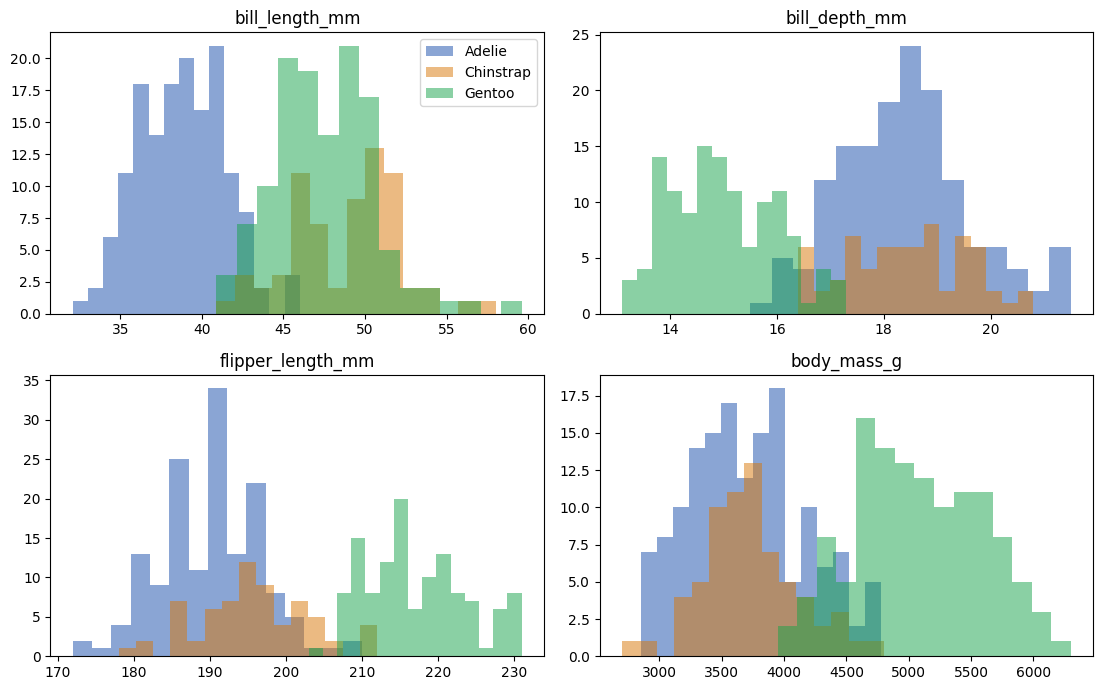

In [6]:
warna = {"Adelie": "#174CAA", "Chinstrap": "#D97706", "Gentoo": "#16A34A"}

fitur = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, f in zip(axes.ravel(), fitur):
    for spesies, w in warna.items():
        nilai = penguin.loc[penguin["species"] == spesies, f]
        ax.hist(nilai, bins=15, alpha=0.5, color=w, label=spesies)
    ax.set_title(f)

axes[0, 0].legend()
plt.tight_layout()
plt.show()

Ada dua hal yang dapat dibaca dari grafik ini:

- **Gentoo mudah dikenali.** Siripnya paling panjang, badannya paling berat, dan paruhnya paling tipis.
- **Adelie dan Chinstrap mirip** pada panjang sirip dan berat badan. Keduanya baru jelas berbeda pada **panjang paruh**.

Tidak ada satu fitur yang mampu memisahkan ketiga spesies, sehingga model perlu menggabungkan keempat fitur.

## E1.4 Membagi Data Latih dan Data Uji

Data dibagi menjadi 75 persen data latih dan 25 persen data uji. `stratify=y` menjaga proporsi spesies tetap sama di kedua bagian, dan `random_state=42` membuat hasilnya dapat diulang.

In [9]:
# Menghapus baris yang memiliki data kosong pada fitur
penguin_bersih = penguin.dropna(subset=fitur)

# Memisahkan fitur dan target
X = penguin_bersih[fitur]
y = penguin_bersih["species"]

# Membagi data latih dan data uji
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

print("Data latih:", X_train.shape, "| data uji:", X_test.shape)
print("Jumlah data setelah dibersihkan:", len(penguin_bersih))

Data latih: (256, 4) | data uji: (86, 4)
Jumlah data setelah dibersihkan: 342


## E1.5 Melatih Model

Saat training, `GaussianNB` menghitung **rata-rata** dan **standar deviasi** setiap fitur untuk setiap spesies, ditambah **prior** setiap spesies. Rumusnya dibahas di modul.

In [10]:
model = GaussianNB()
model.fit(X_train, y_train)

print("Model selesai dilatih. Kelas:", model.classes_)

Model selesai dilatih. Kelas: ['Adelie' 'Chinstrap' 'Gentoo']


## E1.6 Memprediksi Seekor Penguin Baru

Misalkan ditemukan seekor penguin dengan ukuran berikut. Ukurannya sengaja dipilih di antara Adelie dan Chinstrap.

In [11]:
penguin_baru = pd.DataFrame([{
    "bill_length_mm": 44.0,
    "bill_depth_mm": 18.0,
    "flipper_length_mm": 195.0,
    "body_mass_g": 3700.0,
}])

proba = model.predict_proba(penguin_baru)[0]
for spesies, p in zip(model.classes_, proba):
    print(f"{spesies:10s}: {p:.3f}")
print("Prediksi  :", model.predict(penguin_baru)[0])

Adelie    : 0.512
Chinstrap : 0.488
Gentoo    : 0.000
Prediksi  : Adelie


**Hasil yang diharapkan:** Adelie sekitar 0,51 dan Chinstrap sekitar 0,49, sedangkan Gentoo hampir 0. Ukuran penguin ini hampir sama cocoknya dengan kedua spesies, sehingga **prior** yang menentukan: Adelie lebih banyak di data latih (sekitar 44 persen) daripada Chinstrap (sekitar 20 persen), sehingga model memilih Adelie.

## E1.7 Mengevaluasi Model

Sekarang kinerja model diukur pada data uji, yaitu data yang tidak dilihat model saat training.

In [12]:
y_pred = model.predict(X_test)

print(f"Akurasi data uji: {accuracy_score(y_test, y_pred):.3f}")
print()
print(classification_report(y_test, y_pred, digits=3))

Akurasi data uji: 0.988

              precision    recall  f1-score   support

      Adelie      0.974     1.000     0.987        38
   Chinstrap      1.000     0.941     0.970        17
      Gentoo      1.000     1.000     1.000        31

    accuracy                          0.988        86
   macro avg      0.991     0.980     0.986        86
weighted avg      0.989     0.988     0.988        86



*Confusion matrix* memperlihatkan letak kesalahannya. Baris menunjukkan spesies sebenarnya dan kolom menunjukkan hasil prediksi.

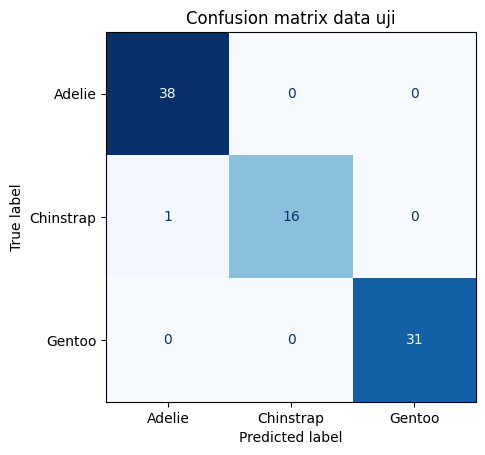

In [13]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues", colorbar=False)
plt.title("Confusion matrix data uji")
plt.show()

Akurasi sekitar 0,99 berarti hampir semua penguin ditebak dengan benar. Angka di diagonal adalah prediksi yang benar. Satu-satunya kesalahan adalah seekor Chinstrap yang ditebak sebagai Adelie, sesuai dengan histogram di E1.3: kedua spesies itu memang mirip, sedangkan Gentoo sangat berbeda.

## E1.8 Latihan

Kerjakan latihan berikut di cell kosong yang tersedia.

**Latihan 1.** Latih `GaussianNB` yang hanya memakai **satu** fitur, yaitu `flipper_length_mm`, dengan pembagian data yang sama. Hitung akurasinya pada data uji, lalu bandingkan dengan model empat fitur.

*Petunjuk:* gunakan `X_train[["flipper_length_mm"]]` dan `X_test[["flipper_length_mm"]]`.

*Hasil yang diharapkan:* akurasi sekitar 0,80, lebih rendah daripada model empat fitur. Jelaskan alasannya dengan melihat histogram panjang sirip di E1.3.

In [16]:
# Latihan 1

# Menggunakan satu fitur saja
X_train_1 = X_train[["flipper_length_mm"]]
X_test_1 = X_test[["flipper_length_mm"]]

# Membuat dan melatih model
model_1 = GaussianNB()
model_1.fit(X_train_1, y_train)

# Prediksi data uji
y_pred_1 = model_1.predict(X_test_1)

# Menghitung akurasi
akurasi_1 = accuracy_score(y_test, y_pred_1)

print("Akurasi model satu fitur:", round(akurasi_1, 3))
print("Akurasi model empat fitur:", round(accuracy_score(y_test, y_pred), 3))


Akurasi model satu fitur: 0.802
Akurasi model empat fitur: 0.988


**Latihan 2.** Buat seekor penguin baru dengan ukuran pilihan Anda sendiri, seperti di E1.6. Prediksi spesiesnya beserta probabilitasnya. Apakah hasilnya sesuai dengan histogram di E1.3?

In [18]:
# Latihan 2
# Membuat data penguin baru

penguin_baru = pd.DataFrame([{
    "bill_length_mm": 50.0,
    "bill_depth_mm": 15.0,
    "flipper_length_mm": 220.0,
    "body_mass_g": 5500.0
}])

# Menghitung probabilitas setiap spesies
proba = model.predict_proba(penguin_baru)[0]

# Menampilkan hasil probabilitas
for spesies, p in zip(model.classes_, proba):
    print(f"{spesies:10s}: {p:.3f}")

# Menampilkan hasil prediksi
print("Prediksi:", model.predict(penguin_baru)[0])

Adelie    : 0.000
Chinstrap : 0.000
Gentoo    : 1.000
Prediksi: Gentoo


Selanjutnya, **Bagian E2** menerapkan Naïve Bayes pada data teks untuk mendeteksi SMS spam.